In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# ===== 1. 填写学号 =====
STUDENT_ID = "20244080317"  # 修改为自己的学号

# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

# ===== 3. 机器指纹（绑定当前电脑） =====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp02
[学号] 20244080317
[机器指纹] 4bdd08838979cc4c
[RUN_ID] 20244080317-4bdd08838979cc4c


## 实验1：NumPy数组、数据类型与索引

In [2]:
# 1. 分别创建整数、浮点数和布尔值 ndarray
arr_int = np.array([1, 2, 3])
arr_float = np.array([1.0, 2.0, 3.0])
arr_bool = np.array([True, False, True])

print("整数数组:", arr_int, "| dtype:", arr_int.dtype, "| shape:", arr_int.shape, "| ndim:", arr_int.ndim)
print("浮点数组:", arr_float, "| dtype:", arr_float.dtype, "| shape:", arr_float.shape, "| ndim:", arr_float.ndim)
print("布尔数组:", arr_bool, "| dtype:", arr_bool.dtype, "| shape:", arr_bool.shape, "| ndim:", arr_bool.ndim)

整数数组: [1 2 3] | dtype: int64 | shape: (3,) | ndim: 1
浮点数组: [1. 2. 3.] | dtype: float64 | shape: (3,) | ndim: 1
布尔数组: [ True False  True] | dtype: bool | shape: (3,) | ndim: 1


In [3]:
# 2. 用 np.arange(12) 创建一维数组，并改变形状
arr_1d = np.arange(12)
print("原始一维数组:", arr_1d)

arr_3x4 = arr_1d.reshape((3, 4))
print("\n形状 (3, 4):\n", arr_3x4)

arr_2x3x2 = arr_1d.reshape((2, 3, 2))
print("\n形状 (2, 3, 2):\n", arr_2x3x2)

原始一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]

形状 (3, 4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2, 3, 2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]


In [4]:
# 3. 对 (3, 4) 的数组完成索引
print("数组内容:\n", arr_3x4)

# 取第 2 行 (索引为1)
row_2 = arr_3x4[1, :]
print("\n第 2 行:", row_2, "| shape:", row_2.shape)

# 取第 1 至第 3 列 (索引为0到2)
cols_1_to_3 = arr_3x4[:, 0:3]
print("\n第 1 至第 3 列:\n", cols_1_to_3, "| shape:", cols_1_to_3.shape)

# 取大于 6 的元素
greater_than_6 = arr_3x4[arr_3x4 > 6]
print("\n大于 6 的元素:", greater_than_6, "| shape:", greater_than_6.shape) 

数组内容:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行: [4 5 6 7] | shape: (4,)

第 1 至第 3 列:
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] | shape: (3, 3)

大于 6 的元素: [ 7  8  9 10 11] | shape: (5,)


In [5]:
# 4. 使用 np.arange(10) 进行条件筛选
arr_10 = np.arange(10)
print("原数组:", arr_10)

# 小于 2 或大于 7
cond_1 = (arr_10 < 2) | (arr_10 > 7)
print("小于 2 或大于 7:", arr_10[cond_1])

# 大于 3 且小于 7
cond_2 = (arr_10 > 3) & (arr_10 < 7)
print("大于 3 且小于 7:", arr_10[cond_2])

原数组: [0 1 2 3 4 5 6 7 8 9]
小于 2 或大于 7: [0 1 8 9]
大于 3 且小于 7: [4 5 6]


In [6]:
# 5. 构造两个 (2, 2) 数组
A = np.array([[1, 2], 
              [3, 4]])
B = np.array([[5, 6], 
              [7, 8]])

print("数组 A:\n", A)
print("数组 B:\n", B)

print("\n--- 逐元素乘法 ---")
print("A * B:\n", A * B)
print("np.multiply(A, B):\n", np.multiply(A, B))

print("\n--- 矩阵乘法 ---")
print("A @ B:\n", A @ B)
print("np.matmul(A, B):\n", np.matmul(A, B))

数组 A:
 [[1 2]
 [3 4]]
数组 B:
 [[5 6]
 [7 8]]

--- 逐元素乘法 ---
A * B:
 [[ 5 12]
 [21 32]]
np.multiply(A, B):
 [[ 5 12]
 [21 32]]

--- 矩阵乘法 ---
A @ B:
 [[19 22]
 [43 50]]
np.matmul(A, B):
 [[19 22]
 [43 50]]


## 实验2：随机抽样、统计与缺失值

In [7]:
# 设置随机种子，保证结果可复现
np.random.seed(42)

# 1. 生成 1000 个均值为 70，标准差为 10 的成绩
scores = np.random.normal(loc=70, scale=10, size=1000)

# 用 np.clip 限制在 0~100 范围内
scores = np.clip(scores, 0, 100)

# 输出统计指标
print("样本数:", len(scores))
print("最小值:", np.min(scores))
print("最大值:", np.max(scores))
print("均值:", np.mean(scores))
print("标准差:", np.std(scores))
print("极差:", np.max(scores) - np.min(scores))

样本数: 1000
最小值: 37.58732659930927
最大值: 100.0
均值: 70.18400443523215
标准差: 9.755086339034765
极差: 62.41267340069073


In [8]:
# 2. 从 np.arange(1, 11) 中不放回抽取 5 个整数
arr_1_to_10 = np.arange(1, 11)

# 均匀抽样（每个数字被抽中的概率相同）
uniform_sample = np.random.choice(arr_1_to_10, size=5, replace=False)
print("均匀抽样:", uniform_sample)

# 按整数大小成比例加权抽样（数字越大，被抽中的概率越大）
# 权重可以直接使用元素本身
weights = arr_1_to_10 / np.sum(arr_1_to_10)
weighted_sample = np.random.choice(arr_1_to_10, size=5, replace=False, p=weights)
print("加权抽样:", weighted_sample)

均匀抽样: [ 4  9  2  6 10]
加权抽样: [10  2  8  9  6]


In [9]:
# 3. 演示随机排列和原地打乱
arr_demo = np.arange(5)
print("原数组:", arr_demo)

# np.random.permutation 返回一个新数组，原数组不变
permuted_arr = np.random.permutation(arr_demo)
print("随机排列后的新数组:", permuted_arr)
print("原数组(未改变):", arr_demo)

# np.random.shuffle 直接在原数组上进行打乱，没有返回值
np.random.shuffle(arr_demo)
print("原地打乱后的原数组:", arr_demo)

原数组: [0 1 2 3 4]
随机排列后的新数组: [4 0 2 1 3]
原数组(未改变): [0 1 2 3 4]
原地打乱后的原数组: [0 4 1 3 2]


In [10]:
# 4. 将模拟成绩的第 10、20、30 个值设为 np.nan (注意索引是从0开始的，所以对应索引9, 19, 29)
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan

# 普通均值（遇到 nan 会直接返回 nan）
mean_ordinary = np.mean(scores_with_nan)

# 忽略缺失值后的均值
mean_ignore_nan = np.nanmean(scores_with_nan)

# 统计缺失值个数
nan_count = np.sum(np.isnan(scores_with_nan))

print("普通均值:", mean_ordinary)
print("忽略缺失值后的均值:", mean_ignore_nan)
print("缺失值个数:", nan_count)

普通均值: nan
忽略缺失值后的均值: 70.19620743160239
缺失值个数: 3


In [11]:
# 5. 将含缺失值的模拟成绩及其序号整理成表格变量（使用 pandas DataFrame）
import pandas as pd

# 创建序号（1 到 1000）
index = np.arange(1, 1001)

# 构造 DataFrame
df_scores = pd.DataFrame({
    "Index": index,
    "Score": scores_with_nan
})

print("前 5 行数据：")
print(df_scores.head())
print("\n数据形状:", df_scores.shape)
# 注意：题目要求“不要写入磁盘”，这里仅仅在内存中创建变量 df_scores

前 5 行数据：
   Index      Score
0      1  74.967142
1      2  68.617357
2      3  76.476885
3      4  85.230299
4      5  67.658466

数据形状: (1000, 2)


## 实验3：SciPy 数值计算与 Matplotlib 可视化

In [12]:
import scipy.linalg as la
import numpy as np

# 方程组: 3x + y = 9, x + 2y = 8
# 系数矩阵 A 和常数向量 b
A = np.array([[3, 1], 
              [1, 2]])
b = np.array([9, 8])

# 求解
solution = la.solve(A, b)
print("求得的解 (x, y):", solution)

# 用 NumPy 代入验证 A @ x 是否等于 b
verification = A @ solution
print("验证 A @ x:", verification)
print("与原 b 相等吗:", np.allclose(verification, b))

求得的解 (x, y): [2. 3.]
验证 A @ x: [9. 8.]
与原 b 相等吗: True


In [13]:
import scipy.optimize as opt

# 定义方程 f(x) = x^2 - 2
def f_root(x):
    return x**2 - 2

# 求正根 (猜测值为 1)
res_pos = opt.root(f_root, x0=1.0)
print("求正根是否成功:", res_pos.success)
print("正根:", res_pos.x[0])
print("正根处的函数值(应接近0):", f_root(res_pos.x[0]))

# 求负根 (猜测值为 -1)
res_neg = opt.root(f_root, x0=-1.0)
print("\n求负根是否成功:", res_neg.success)
print("负根:", res_neg.x[0])
print("负根处的函数值(应接近0):", f_root(res_neg.x[0]))

求正根是否成功: True
正根: 1.4142135623730947
正根处的函数值(应接近0): -8.881784197001252e-16

求负根是否成功: True
负根: -1.4142135623730947
负根处的函数值(应接近0): -8.881784197001252e-16


In [14]:
# 定义目标函数 f(x) = x^2 + x + 2
def f_min(x):
    return x**2 + x + 2

# 求极小值 (任意初始猜测值，比如 0)
res_min = opt.minimize(f_min, x0=0.0)

print("极小值点 x:", res_min.x[0])
print("极小值 f(x):", res_min.fun)
print("--- 与解析结果比较 ---")
print("解析极小值点 x = -1/2 = -0.5")
print("解析极小值 f(-0.5) = 1.75")

极小值点 x: -0.5000000064345924
极小值 f(x): 1.75
--- 与解析结果比较 ---
解析极小值点 x = -1/2 = -0.5
解析极小值 f(-0.5) = 1.75


In [15]:
import scipy.stats as stats
import numpy as np

# 固定随机种子
np.random.seed(42)

# 生成两组样本，各100个
group1 = np.random.normal(loc=0, scale=1, size=100)
group2 = np.random.normal(loc=1, scale=1, size=100)

# 进行独立样本 t 检验
t_stat, p_val = stats.ttest_ind(group1, group2)

print(f"t 统计量: {t_stat:.4f}")
print(f"p 值: {p_val:.4e}")

# 判断
alpha = 0.05
if p_val < alpha:
    print(f"因为 p 值 < {alpha}，拒绝原假设，两组样本存在显著差异。")
else:
    print(f"因为 p 值 >= {alpha}，不能拒绝原假设，无显著差异。")

t 统计量: -8.5515
p 值: 3.2930e-15
因为 p 值 < 0.05，拒绝原假设，两组样本存在显著差异。


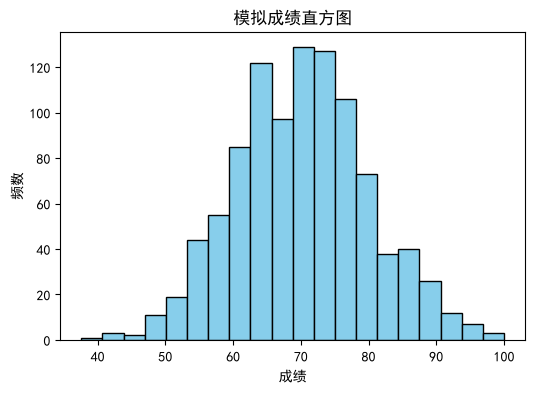

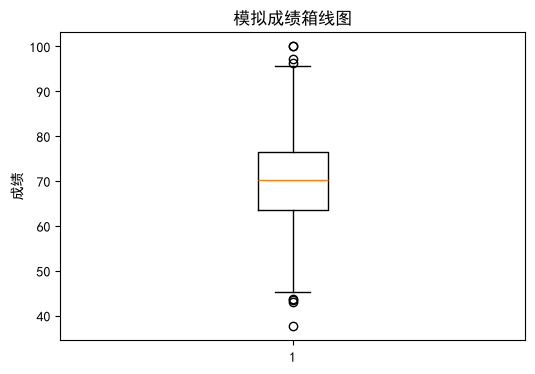

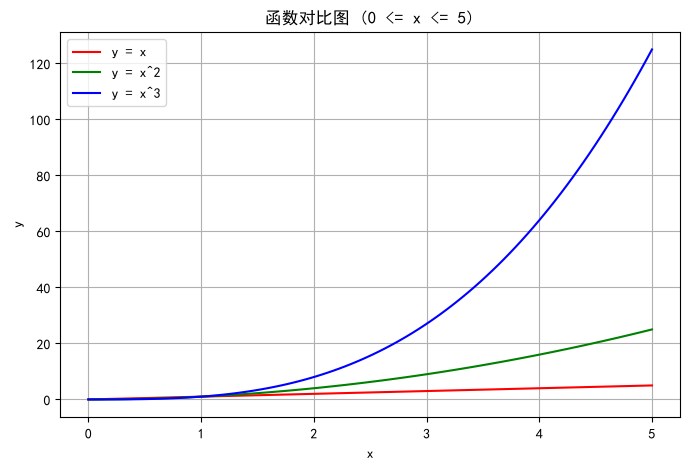

In [16]:
import matplotlib.pyplot as plt

# 设置中文字体，防止中文显示为方块
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 默认黑体
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# (1) 为实验2的有效成绩画直方图
plt.figure(figsize=(6, 4))
plt.hist(scores, bins=20, color='skyblue', edgecolor='black')
plt.title("模拟成绩直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.show()

# (2) 为实验2的有效成绩画箱线图
plt.figure(figsize=(6, 4))
plt.boxplot(scores)
plt.title("模拟成绩箱线图")
plt.ylabel("成绩")
plt.show()

# (3) 绘制 y = x, y = x^2, y = x^3 的折线图
# 生成 0~5 之间的 x 值
x_vals = np.linspace(0, 5, 100)

plt.figure(figsize=(8, 5))
plt.plot(x_vals, x_vals, label='y = x', color='red')
plt.plot(x_vals, x_vals**2, label='y = x^2', color='green')
plt.plot(x_vals, x_vals**3, label='y = x^3', color='blue')

plt.title("函数对比图 (0 <= x <= 5)")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()  # 显示图例
plt.grid(True)
plt.show()

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

In [17]:
import pandas as pd
import numpy as np

# 给定的模拟数据
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

# 创建 DataFrame，行索引为姓名
df = pd.DataFrame(records).set_index("Name")

# 计算 Total 和 Average 两列
df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1)

print("行索引:", df.index.tolist())
print("列名:", df.columns.tolist())
print("\n前 3 行数据:")
print(df.head(3))
print("\n基本统计信息:")
print(df.describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名: ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行数据:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [18]:
# 用 loc 读取 Carol 的记录（基于行标签）
print("loc 读取 Carol:")
print(df.loc["Carol"])

# 用 iloc 读取 Carol 的记录（Carol 是第 3 行，索引为 2）
print("\niloc 读取 Carol:")
print(df.iloc[2])

# 筛选平均分不低于 80 的学生
high_avg_students = df[df["Average"] >= 80]
print("\n平均分 >= 80 的学生:")
print(high_avg_students)

loc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取 Carol:
Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分 >= 80 的学生:
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [19]:
# 计算三科成绩的列均值 (axis=0)
col_means = df[["Math", "English", "Python"]].mean(axis=0)
print("三科成绩列均值:")
print(col_means)

# 计算每名学生的行均值 (axis=1)
row_means = df[["Math", "English", "Python"]].mean(axis=1)
print("\n每名学生的三科行均值:")
print(row_means)

三科成绩列均值:
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的三科行均值:
Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64


In [20]:
# 1. 使用 apply() 计算每名学生的三科最高分
df["Max_Score"] = df[["Math", "English", "Python"]].apply(np.max, axis=1)
print("每名学生的三科最高分:")
print(df["Max_Score"])

# 2. 使用 agg() 一次得到每科的最小值、均值和最大值
agg_results = df[["Math", "English", "Python"]].agg(["min", "mean", "max"])
print("\n每科的最小值、均值和最大值:")
print(agg_results)

# 3. 任选一列使用 rank() 排名 (这里选 Python 成绩)
df["Python_Rank"] = df["Python"].rank(ascending=False)
print("\nPython 成绩排名 (分数高者排前):")
print(df[["Python", "Python_Rank"]])

每名学生的三科最高分:
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Max_Score, dtype: int64

每科的最小值、均值和最大值:
           Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000

Python 成绩排名 (分数高者排前):
       Python  Python_Rank
Name                      
Alice      95          1.0
Bob        80          5.0
Carol      89          2.0
David      70          6.0
Eva        86          3.0
Frank      82          4.0


In [21]:
# 按 Group 分组，统计每组人数和三科平均分
group_stats = df.groupby("Group").agg(
    Count=("Math", "count"),
    Math_Mean=("Math", "mean"),
    English_Mean=("English", "mean"),
    Python_Mean=("Python", "mean")
)
print("分组统计结果:")
print(group_stats)

# 用 transform('mean') 为每行增加其所在组的 Python 平均分
df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加所在组 Python 平均分后的数据:")
print(df[["Group", "Python", "Group_Python_Mean"]])

分组统计结果:
       Count  Math_Mean  English_Mean  Python_Mean
Group                                             
A          3  79.666667     83.333333    87.000000
B          3  80.000000     78.333333    80.333333

增加所在组 Python 平均分后的数据:
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


In [22]:
# 保留 Python 平均分不低于 80 的组
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)

# 因为 A 组 Python 均分为 (95+79+86)/3 = 86.67 (保留)
# B 组 Python 均分为 (89+70+82)/3 = 80.33 (保留)
# 假设有的组平均分低于 80 就会被剔除。这里两组都符合，所以全保留。
print("过滤后的组和学生:")
print(filtered_df[["Group", "Python"]])

过滤后的组和学生:
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


In [23]:
# 保留 Python 平均分不低于 80 的组
filtered_df = df.groupby("Group").filter(lambda x: x["Python"].mean() >= 80)

# 因为 A 组 Python 均分为 (95+79+86)/3 = 86.67 (保留)
# B 组 Python 均分为 (89+70+82)/3 = 80.33 (保留)
# 假设有的组平均分低于 80 就会被剔除。这里两组都符合，所以全保留。
print("过滤后的组和学生:")
print(filtered_df[["Group", "Python"]])

过滤后的组和学生:
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82
